# One-to-one cell matching across two imaging rounds (DAPI vs H&E)

Multi-round imaging of **one physical tissue section** is now routine: an
in-situ transcriptomics or multiplexed-immunofluorescence run images the
nuclei with **DAPI**, and the same slide is later stained with **H&E** for
pathology. Each round is segmented on its own, so you end up with two lists
of cell centroids in two unrelated pixel frames. To carry information across
rounds — a pathologist's annotation onto the molecular cells, or protein
intensities onto the transcriptome — you need to know **which DAPI nucleus is
which H&E nucleus**.

The two frames differ by

- a **global similarity**: shift, rotation, a small scale change, and
  sometimes a **mirror flip** (the slide went in upside down);
- a **smooth non-rigid deformation** from coverslipping, destaining and
  re-staining, which can exceed a cell diameter;
- **partial overlap** of the imaged fields;
- **independent segmentation**: cells missing, split or invented on either
  side.

`ov.space.geom` provides four functions for this problem:

| Function | What it does |
|---|---|
| `hematoxylin_channel(rgb)` | colour deconvolution of an RGB H&E image into a nuclear (haematoxylin) image that looks like DAPI |
| `nn_spacing(xy)` | median nearest-neighbour distance — the natural length unit for every tolerance |
| `register_images(fixed, moving)` | deformable image registration; returns a mapping *fixed (x, y) → moving (x, y)* |
| `match_cells(fixed_xy, moving_xy, ...)` | **one-to-one** cell correspondence, from centroids alone or helped by the images |

**How `match_cells` works.** *With centroids only*: (1) both point sets are
rendered as Gaussian density maps and every flip × rotation × scale on a grid
is scored by FFT cross-correlation (which also gives the translation);
(2) a robust affine is fitted on mutual nearest neighbours within a shrinking
radius; (3) a smoothed thin-plate spline follows the non-rigid part, fitted
only on pairs whose displacement agrees with their neighbours; (4) the
Hungarian algorithm assigns cells one-to-one under a distance cap, so cells
without a partner stay unmatched. *With images*, steps 1–3 are replaced by
`register_images` (patch-voting global pose + coarse-to-fine block matching),
because cell positions are nearly random and carry little to register on,
while tissue texture carries a lot. Both paths finish with a **prune-and-grow**
pass that drops pairs disagreeing with their neighbours and re-assigns the
unmatched cells using the local deformation of their matched neighbours.

In this tutorial we build a section with a **known ground truth**, image it
twice, and measure precision and recall of every variant.

In [1]:
import importlib.util
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage
from skimage.color import rgb_from_hed

import omicverse as ov
ov.plot_set(ipython_format='png')      # plain PNG (default 'retina') keeps the notebook light

# OpenCV is optional: register_images uses it for a final affine-ECC repair of
# strongly stretched blocks and skips that step (with a warning) without it.
ECC_ROUNDS = 3 if importlib.util.find_spec("cv2") else 0
print("OpenCV available:", ECC_ROUNDS > 0)

🔬 Starting plot initialization...
🧬 Detecting GPU devices…
🚫 No GPU devices found (CUDA/MPS/ROCm/XPU)

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.3.2   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.

OpenCV available: False


## 1. Simulate one section imaged twice

We place nuclei in a 600 × 600 px section with a minimum spacing (a
hard-core point process — real nuclei do not overlap) and a smoothly varying
density, so the tissue has dense and sparse regions like epithelium and
stroma. Then we image it twice:

- **round 1 — DAPI (fixed)**: a 400 × 400 px field cut from the section,
  with shot noise and uneven brightness;
- **round 2 — H&E (moving)**: a 520 × 520 px RGB field of the same section,
  rotated by 23°, scaled by 1.06, shifted, and bent by a sinusoidal
  deformation with an amplitude of 14 px — slightly *more* than one cell
  spacing. The colours are produced with the Beer–Lambert law from
  haematoxylin (nuclei) and eosin (cytoplasm / stroma) optical densities.

Because we built the transform, `truth_map(p)` gives the exact moving-image
position of every fixed-image point, and every centroid carries the id of
the physical nucleus it came from.

In [2]:
rng = np.random.default_rng(7)
S = 600                                     # section size (px)

def hard_core_points(n, size, rmin, rng):
    """Dart throwing: uniform points, none closer than rmin."""
    acc = np.empty((0, 2))
    for p in rng.uniform(0, size, (n * 6, 2)):
        if len(acc) == 0 or np.min(np.hypot(*(acc - p).T)) >= rmin:
            acc = np.vstack([acc, p])
            if len(acc) >= n:
                break
    return acc

tissue = hard_core_points(1500, S, 11.0, rng)
# smooth density field -> dense and sparse regions
dens = ndimage.gaussian_filter(rng.random((S // 10 + 1, S // 10 + 1)), 3)
dens = (dens - dens.min()) / (dens.max() - dens.min())
keep = rng.random(len(tissue)) < 0.35 + 0.65 * dens[(tissue[:, 1] // 10).astype(int),
                                                     (tissue[:, 0] // 10).astype(int)]
tissue = tissue[keep]
radius = rng.uniform(3.0, 4.5, len(tissue))          # nuclear radius (px)
print(f"{len(tissue)} nuclei in the section")

def render(pts, rad, shape):
    """Sum of Gaussian blobs, one per nucleus."""
    img = np.zeros(shape)
    H, W = shape
    yy, xx = np.mgrid[0:H, 0:W]
    for (x, y), r in zip(pts, rad):
        x0, x1 = int(max(x - 3 * r, 0)), int(min(x + 3 * r + 1, W))
        y0, y1 = int(max(y - 3 * r, 0)), int(min(y + 3 * r + 1, H))
        if x1 > x0 and y1 > y0:
            img[y0:y1, x0:x1] += np.exp(-((xx[y0:y1, x0:x1] - x) ** 2 +
                                          (yy[y0:y1, x0:x1] - y) ** 2) / (2 * (0.6 * r) ** 2))
    return img

# --- round 1: DAPI, a 400 x 400 field with origin (100, 100) in the section
OFF_F, HF = np.array([100.0, 100.0]), 400
dapi = render(tissue - OFF_F, radius, (HF, HF))
dapi *= ndimage.gaussian_filter(rng.random((HF, HF)), 40) * 0.6 + 0.7   # uneven illumination
dapi = np.clip(dapi + rng.normal(0, 0.03, dapi.shape), 0, None)

# --- round 2: H&E, rotated / scaled / shifted / non-rigidly warped
THETA, SCALE, WARP = 23.0, 1.06, 14.0
t = np.deg2rad(THETA)
R = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]]) * SCALE

def section_to_moving(p):
    q = (np.asarray(p, float) - S / 2) @ R.T + np.array([260.0, 250.0])
    return q + WARP * np.c_[np.sin(q[:, 1] / 85.0), np.cos(q[:, 0] / 100.0)]

def truth_map(p_fixed):
    """Ground-truth mapping fixed (x, y) -> moving (x, y)."""
    return section_to_moving(np.asarray(p_fixed, float) + OFF_F)

HM = 520
mov_true = section_to_moving(tissue)
hem = render(mov_true, radius * SCALE, (HM, HM))                       # haematoxylin OD
eos = ndimage.gaussian_filter(render(mov_true, radius * SCALE * 2.2, (HM, HM)), 3) + 0.25
od = np.stack([0.9 * hem, 0.35 * eos, np.zeros_like(hem)], -1) @ rgb_from_hed
he_rgb = np.clip(255 * np.exp(-od * np.log(10)), 0, 255).astype(np.uint8)  # Beer-Lambert
print("DAPI image:", dapi.shape, "  H&E image:", he_rgb.shape, he_rgb.dtype)

941 nuclei in the section
DAPI image: (400, 400)   H&E image: (520, 520, 3) uint8


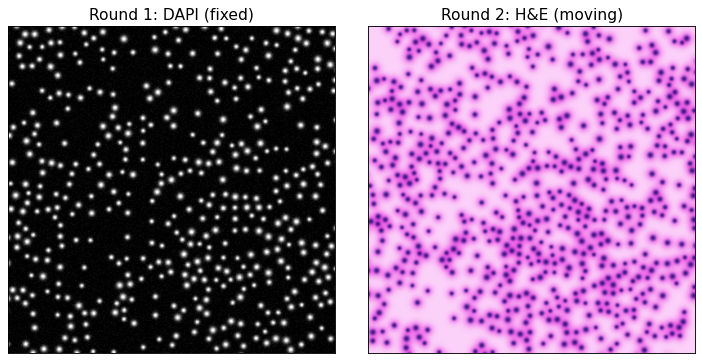

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.4), constrained_layout=True)
axes[0].imshow(dapi, cmap="gray", vmax=np.percentile(dapi, 99.5))
axes[0].set_title("Round 1: DAPI (fixed)")
axes[1].imshow(he_rgb)
axes[1].set_title("Round 2: H&E (moving)")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

The two images show the same nuclei, but nothing lines up: the H&E field is
turned by about 23°, larger, offset, and gently bent. Notice also that the
**contrast is opposite**: in DAPI nuclei are bright on black, in H&E they are
dark purple on pink. Registration needs both images to show the same thing
bright — that is the job of the next function.

## 2. From H&E colour to a nuclear image: `hematoxylin_channel`

**Colour deconvolution** (Ruifrok & Johnston, 2001) works in optical-density
space, where stains add linearly (Beer–Lambert): `OD = -log10(I / I0)`. Each
stain has a fixed OD colour vector; inverting the 3 × 3 stain matrix splits
every pixel into haematoxylin, eosin and DAB amounts. `hematoxylin_channel`
keeps the haematoxylin amount (which binds nuclear chromatin) and rescales it
to [0, 1] by its 1st–99.5th percentiles — bright where the nuclei are, just
like DAPI.

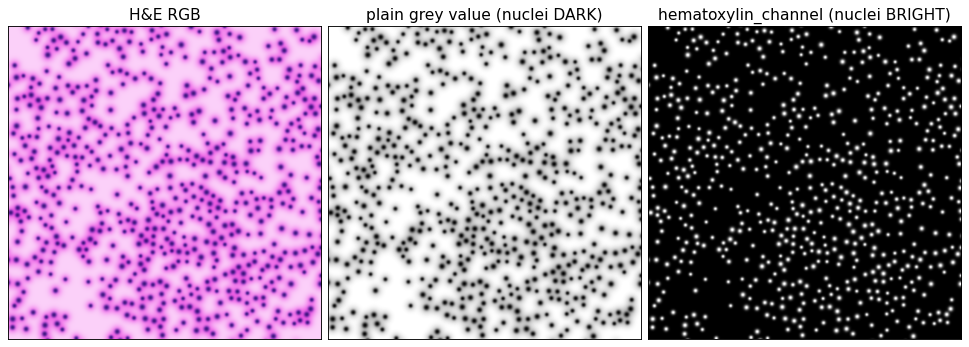

corr(haematoxylin channel, true haematoxylin density) = 1.000
corr(grey value,               true haematoxylin density) = -0.924


In [4]:
he_nuc = ov.space.geom.hematoxylin_channel(he_rgb)
grey = he_rgb.mean(-1)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), constrained_layout=True)
axes[0].imshow(he_rgb); axes[0].set_title("H&E RGB")
axes[1].imshow(grey, cmap="gray"); axes[1].set_title("plain grey value (nuclei DARK)")
axes[2].imshow(he_nuc, cmap="gray"); axes[2].set_title("hematoxylin_channel (nuclei BRIGHT)")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

print(f"corr(haematoxylin channel, true haematoxylin density) = {np.corrcoef(he_nuc.ravel(), hem.ravel())[0, 1]:.3f}")
print(f"corr(grey value,               true haematoxylin density) = {np.corrcoef(grey.ravel(), hem.ravel())[0, 1]:.3f}")

The haematoxylin channel reproduces the simulated nuclear stain almost
perfectly (correlation ≈ 1), while the plain grey value is **anti**-correlated
with it and also mixes in the eosin signal. Feeding a grey H&E image to a
registration against DAPI therefore asks it to align bright nuclei with dark
nuclei — one of the most common silent failures.

The same call works on real brightfield images. Below it is applied to the
immunohistochemistry image bundled with scikit-image (haematoxylin
counterstain + DAB); only the blue nuclear counterstain survives.

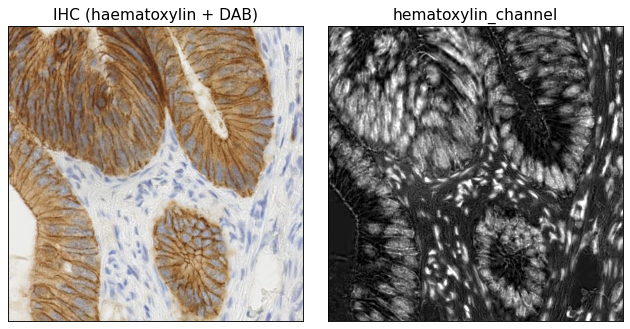

In [5]:
from skimage import data as skdata

ihc = skdata.immunohistochemistry()
ihc_nuc = ov.space.geom.hematoxylin_channel(ihc)
fig, axes = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)
axes[0].imshow(ihc); axes[0].set_title("IHC (haematoxylin + DAB)")
axes[1].imshow(ihc_nuc, cmap="gray"); axes[1].set_title("hematoxylin_channel")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

## 3. Two independent segmentations

A real pipeline would segment nuclei in each image (e.g. with
`ov.space` cellpose / StarDist backends). To keep the ground truth exact we
simulate the segmentation outcome directly, with the error modes that real
segmenters produce:

- **centroid jitter** of 0.8 px;
- **dropout**: each segmentation independently misses 7 % of nuclei;
- **spurious detections**: 6 % extra objects (debris, split nuclei) on each side;
- **partial overlap**: only nuclei inside each field are seen.

Every true centroid keeps the section id of its nucleus; spurious ones get
negative ids. A pair is *correct* when both sides carry the same id.

In [6]:
def segment(true_xy, field_size, keep_rate, extra_rate, id_offset, rng):
    inside = np.all((true_xy > 3) & (true_xy < field_size - 3), axis=1)
    kept = inside & (rng.random(len(true_xy)) < keep_rate)
    xy = true_xy[kept] + rng.normal(0, 0.8, (kept.sum(), 2))
    n_extra = int(extra_rate * kept.sum())
    xy = np.vstack([xy, rng.uniform(3, field_size - 3, (n_extra, 2))])
    ids = np.r_[np.where(kept)[0], id_offset - np.arange(n_extra)]
    return xy, ids, kept

fixed_xy, fixed_ids, kept_f = segment(tissue - OFF_F, HF, 0.93, 0.06, -1, rng)
moving_xy, moving_ids, kept_m = segment(mov_true, HM, 0.93, 0.06, -100000, rng)
truth = set(np.where(kept_f & kept_m)[0])         # nuclei segmented in BOTH rounds

pd.DataFrame({
    "cells segmented": [len(fixed_xy), len(moving_xy)],
    "of which spurious": [(fixed_ids < 0).sum(), (moving_ids < 0).sum()],
    "true partner exists on other side": [len(truth), len(truth)],
}, index=["DAPI (fixed)", "H&E (moving)"])

              cells segmented  of which spurious  \
DAPI (fixed)              426                 24   
H&E (moving)              595                 33   

              true partner exists on other side  
DAPI (fixed)                                369  
H&E (moving)                                369  

Only 369 nuclei can possibly be matched: the H&E field covers more tissue,
every segmentation misses some nuclei, and both invented some. **A correct
answer leaves the rest unmatched** — about 13 % of the DAPI cells and 38 % of
the H&E cells here; a method that pairs every cell is guaranteed to be wrong
for them.

## 4. The length unit: `nn_spacing`

Every distance in `match_cells` is expressed in units of the median
nearest-neighbour spacing of the fixed cells, so the same call works in
pixels or microns, at any magnification. In particular, the default
acceptance cap is `max_distance = 0.5 × spacing`: a candidate farther than
half a cell spacing is more likely a *neighbour* than the same cell.

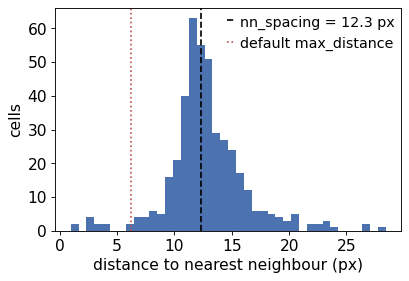

spacing = 12.33 px;  deformation amplitude = 14.0 px = 1.14 x spacing


In [7]:
spacing = ov.space.geom.nn_spacing(fixed_xy)
from scipy.spatial import cKDTree
d_nn = cKDTree(fixed_xy).query(fixed_xy, k=2)[0][:, 1]

fig, ax = plt.subplots(figsize=(5, 3.4), constrained_layout=True)
ax.hist(d_nn, bins=40, color="#4C72B0")
ax.axvline(spacing, color="k", ls="--", label=f"nn_spacing = {spacing:.1f} px")
ax.axvline(0.5 * spacing, color="#C44E52", ls=":", label="default max_distance")
ax.set_xlabel("distance to nearest neighbour (px)"); ax.set_ylabel("cells")
ax.legend(frameon=False)
plt.show()
print(f"spacing = {spacing:.2f} px;  deformation amplitude = {WARP} px = {WARP / spacing:.2f} x spacing")

The spacing is about 12.7 px. The deformation we applied (14 px) is **larger
than one spacing**, i.e. after the best global transform many cells still sit
closer to a neighbour's partner than to their own. This is exactly the regime
where centroids alone become ambiguous.

## 5. Matching from centroids only

Without images, `match_cells` searches the full circle of rotations (2° steps),
scales 0.8–1.25 and both mirror orientations, then refines. We score the
result against the ground truth with

- **precision** = correct pairs / reported pairs,
- **recall** = correct pairs / nuclei that have a partner.

In [8]:
def score(pairs, label):
    correct = int((pairs.moving_id.values == pairs.fixed_id.values).sum())
    return pd.Series({"pairs": len(pairs), "correct": correct,
                      "precision": correct / max(len(pairs), 1),
                      "recall": correct / len(truth),
                      "median distance / spacing": pairs.distance.median() / spacing},
                     name=label)

t0 = time.time()
pairs_pts, info_pts = ov.space.geom.match_cells(
    fixed_xy, moving_xy, fixed_ids=fixed_ids, moving_ids=moving_ids, return_info=True)
print(f"point-only matching: {time.time() - t0:.0f} s")

A = info_pts["affine_matrix"]
print(f"recovered affine: det = {np.linalg.det(A):+.3f} (negative = mirrored), "
      f"scale = {np.sqrt(abs(np.linalg.det(A))):.3f}, "
      f"rotation = {np.degrees(np.arctan2(A[1, 0], A[0, 0])):.1f} deg (moving -> fixed)")
score(pairs_pts, "centroids only").to_frame().T.round(3)

point-only matching: 26 s
recovered affine: det = +0.820 (negative = mirrored), scale = 0.906, rotation = -25.3 deg (moving -> fixed)


                pairs  correct  precision  recall  median distance / spacing
centroids only  282.0    189.0       0.67   0.512                      0.058

The global pose is found: a rotation of about −25° and a scale of about 0.91,
close to the inverse of what we applied (−23°, 1/1.06 = 0.94) because
`match_cells` maps *moving onto fixed*; the remaining difference is the
average turn and stretch of the sinusoidal deformation over this field. The
result is the one-to-one table `moving_id, fixed_id, distance`.

Precision and recall, however, are far from perfect (about 0.67 and 0.51):
with a deformation larger than a cell spacing, the spline that follows the
bend is fitted on nearest-neighbour pairs, and in the most bent regions those
pairs are wrong. This is the documented limit of the point-only path — **pass
the images whenever you have them**.

Note also the last column: the median residual distance is small (≈ 6 % of
a spacing) even though a third of the pairs are wrong. A spline fitted to
wrong pairs pulls them together, so **a small matching distance is not
evidence of a correct match** — only an independent check (here the ground
truth; in practice the image overlay of section 6 or a marker shared by both
rounds) is.

## 6. Registering the images: `register_images`

`register_images(fixed, moving)` returns a callable mapping fixed (x, y) to
moving (x, y):

1. **Global pose by patch voting.** Small, textured fixed patches are
   template-matched (normalised cross-correlation) against the moving image
   under every flip × rotation × scale on a grid (8° steps by default); each
   patch votes for a translation. Small patches stay almost rigid under a
   deformation that ruins any whole-image correlation, so the right pose is the
   one most patches agree on.
2. **Deformable refinement by block matching**, coarse to fine: a grid of
   blocks is matched against the moving image warped by the current mapping;
   displacements that disagree with their neighbours are dropped, the rest are
   interpolated by a smoothed thin-plate spline and composed onto the mapping.
3. Optionally an **affine ECC** repair (OpenCV) of strongly stretched blocks.

`moving_rgb=True` converts the H&E image with `hematoxylin_channel` first.
The full pose search is the slow part (a few minutes on 2 CPUs).

In [9]:
t0 = time.time()
mapping, reg = ov.space.geom.register_images(dapi, he_rgb, moving_rgb=True,
                                             ecc_rounds=ECC_ROUNDS, return_info=True)
print(f"register_images: {time.time() - t0:.0f} s")

# accuracy of the mapping against the ground truth on a grid of fixed pixels
gy, gx = np.mgrid[10:HF - 10:10, 10:HF - 10:10]
grid = np.c_[gx.ravel(), gy.ravel()].astype(float)
err = np.linalg.norm(mapping(grid) - truth_map(grid), axis=1)
pd.Series({"rotation (deg, fixed->moving)": reg["rotation"], "scale": reg["scale"],
           "flip": reg["flip"], "vote fraction": reg["vote_fraction"],
           "final image correlation": reg["final_correlation"],
           "overlap fraction": reg["overlap_fraction"],
           "median error (px)": np.median(err),
           "95th pct error (px)": np.percentile(err, 95),
           "95th pct error / spacing": np.percentile(err, 95) / spacing}).to_frame("value").round(3)

register_images: 155 s


                                  value
rotation (deg, fixed->moving)     334.0
scale                              0.92
flip                              False
vote fraction                  0.671875
final image correlation        0.990106
overlap fraction               0.979163
median error (px)                0.1556
95th pct error (px)            0.652805
95th pct error / spacing       0.052954

How to read `info`:

- `rotation`, `scale`, `flip` — the global pose found by the vote, expressed
  as the transform that brings the H&E onto the DAPI frame: 334° ≈ −26°
  (true −23°) and 0.92 (true 1/1.06 = 0.94). These are grid values (8° steps,
  refined by ±4°); the remaining few degrees and percent, like the bend
  itself, are taken up by the deformable stage;
- `vote_fraction` — share of patches agreeing on that pose; well above 1/2
  means an unambiguous pose, a value near the chance level means the images
  do not share structure (wrong channel, wrong section);
- `final_correlation` — correlation of the fixed image with the warped moving
  image over the overlap: ≈ 0.99 here;
- with OpenCV missing (as in this environment) the ECC repair is skipped;
  this synthetic deformation does not need it.

Against the ground truth the mapping is accurate to a fraction of a pixel
almost everywhere — far below the cell spacing, which is what makes
one-to-one matching easy afterwards. A visual check is the colour overlay:
DAPI in magenta, the warped haematoxylin channel in green; correctly aligned
nuclei turn white.

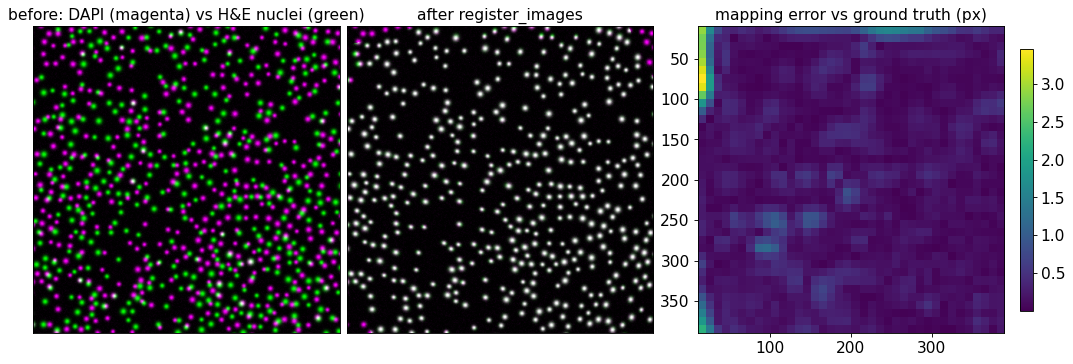

In [10]:
yy, xx = np.mgrid[0:HF, 0:HF]
q = mapping(np.c_[xx.ravel(), yy.ravel()].astype(float))
warped_nuc = ndimage.map_coordinates(he_nuc, [q[:, 1], q[:, 0]], order=1, cval=0).reshape(HF, HF)
naive = he_nuc[:HF, :HF]                                    # no registration

def overlay(a, b):
    a = np.clip(a / np.percentile(a, 99.5), 0, 1); b = np.clip(b / np.percentile(b, 99.5), 0, 1)
    return np.dstack([a, b, a])

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), constrained_layout=True)
axes[0].imshow(overlay(dapi, naive)); axes[0].set_title("before: DAPI (magenta) vs H&E nuclei (green)")
axes[1].imshow(overlay(dapi, warped_nuc)); axes[1].set_title("after register_images")
im = axes[2].imshow(err.reshape(gx.shape), cmap="viridis", extent=(10, HF - 10, HF - 10, 10))
axes[2].set_title("mapping error vs ground truth (px)")
plt.colorbar(im, ax=axes[2], shrink=0.8)
for ax in axes[:2]:
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

Before registration the two channels never coincide; after it, the nuclei are
white throughout the field. The error map shows where the mapping is least
certain — typically the field borders and nuclei-poor (stromal) regions,
where blocks have little texture to lock on to.

## 7. Image-assisted matching

Pass the images to `match_cells` and it uses `register_images` internally,
inverts the mapping to bring the moving cells into the fixed frame, refines
with the coherent spline, assigns one-to-one and prunes/grows. Unless you pin
`local_affine` in `image_kwargs`, it tries **both** block-matching variants
(translation-only and local-affine) and keeps the one that lines up more cells
one-to-one — a RANSAC-style consensus criterion.

The global pose search is the expensive part, and we already know the pose
from section 6. As the docstring recommends, we narrow the grid around it:
this is faster, not more accurate.

In [11]:
pose_kw = dict(rotations=reg["rotation"] + np.array([-8.0, 0.0, 8.0]),
               scales=[reg["scale"]], allow_flip=False, ecc_rounds=ECC_ROUNDS)
t0 = time.time()
pairs_img, info_img = ov.space.geom.match_cells(
    fixed_xy, moving_xy, fixed_ids=fixed_ids, moving_ids=moving_ids,
    fixed_image=dapi, moving_image=he_rgb, moving_rgb=True,
    image_kwargs=pose_kw, return_info=True)
print(f"image-assisted matching: {time.time() - t0:.0f} s")
print("pairs per variant [translation-only, local-affine]:",
      info_img["registration"]["n_pairs_by_variant"])
print(f"direct assignments: {info_img['n_direct']}, recovered by prune-and-grow: {info_img['n_grown']}")

summary = pd.concat([score(pairs_pts, "centroids only"),
                     score(pairs_img, "centroids + images")], axis=1).T
summary.round(3)

image-assisted matching: 57 s
pairs per variant [translation-only, local-affine]: [370, 370]
direct assignments: 370, recovered by prune-and-grow: 0


                    pairs  correct  precision  recall  \
centroids only      282.0    189.0      0.670   0.512   
centroids + images  370.0    369.0      0.997   1.000   

                    median distance / spacing  
centroids only                          0.058  
centroids + images                      0.055  

With the images, every nucleus that exists in both rounds is matched (recall
1.0) and only one of 370 pairs is wrong (precision 0.997) — against 0.67 /
0.51 from centroids alone. Both variants found the same number of pairs, and
the direct assignment already found them all, so prune-and-grow had nothing
left to recover. The single wrong pair involves a spurious detection that
happened to fall within half a spacing of a real nucleus on the other side:
no geometric method can tell those apart.

Below, matched pairs are drawn as segments from the warped moving position to
the fixed centroid (green = correct, red = wrong) for both runs, with the
unmatched cells marked.

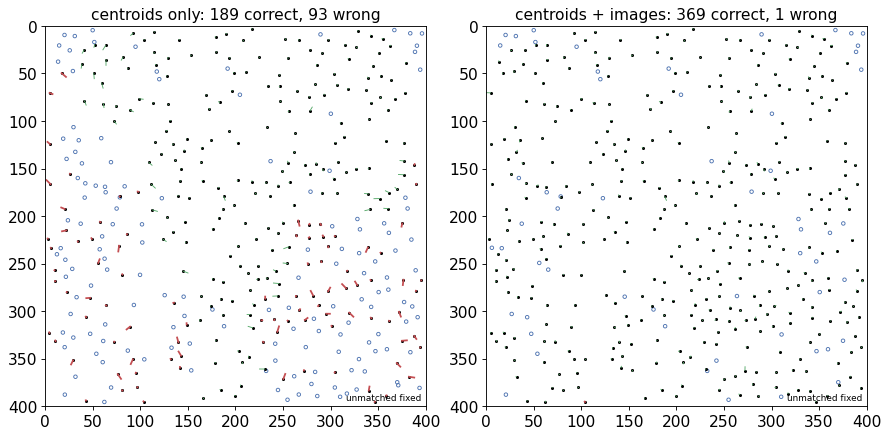

In [12]:
def draw_pairs(ax, pairs, warped, title):
    fpos = dict(zip(fixed_ids, fixed_xy))
    midx = {m: i for i, m in enumerate(moving_ids)}
    ok = pairs.moving_id.values == pairs.fixed_id.values
    for (mid, fid), good in zip(pairs[["moving_id", "fixed_id"]].values, ok):
        a, b = warped[midx[mid]], fpos[fid]
        ax.plot([a[0], b[0]], [a[1], b[1]], color="#55A868" if good else "#C44E52",
                lw=1.6 if not good else 0.8)
    unf = ~np.isin(fixed_ids, pairs.fixed_id)
    ax.scatter(*fixed_xy[unf].T, s=10, facecolor="none", edgecolor="#4C72B0", lw=0.8,
               label="unmatched fixed")
    ax.scatter(*fixed_xy[~unf].T, s=3, color="k")
    ax.set_xlim(0, HF); ax.set_ylim(HF, 0); ax.set_aspect("equal")
    ax.set_title(f"{title}: {ok.sum()} correct, {(~ok).sum()} wrong")
    ax.legend(loc="lower right", fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), constrained_layout=True)
draw_pairs(axes[0], pairs_pts, info_pts["warped_moving"], "centroids only")
draw_pairs(axes[1], pairs_img, info_img["warped_moving"], "centroids + images")
plt.show()

In the point-only run the wrong pairs (red) and the unmatched cells cluster
where the sinusoidal bend is strongest: there a cell's nearest neighbour after
the affine is often the partner of the cell next to it, and the spline is
trained on those wrong pairs. The image-assisted run has no such region.
Unmatched fixed cells in the right-hand panel are exactly the nuclei missed by
the H&E segmentation, plus the spurious DAPI detections — they *should* stay
unmatched.

## 8. Precision vs recall: `max_distance`

`max_distance` caps the accepted distance after warping (default
`0.5 × spacing`). A larger cap admits more pairs where the warp is imperfect
(recall ↑) but also more neighbours mistaken for partners (precision ↓). We
sweep it on the harder point-only problem.

In [13]:
rows = []
for k in [0.2, 0.35, 0.5, 0.75, 1.0]:
    p = ov.space.geom.match_cells(fixed_xy, moving_xy, fixed_ids=fixed_ids, moving_ids=moving_ids,
                                  max_distance=k * spacing)
    rows.append(score(p, k))
sweep = pd.DataFrame(rows).rename_axis("max_distance / spacing")
sweep.round(3)

                        pairs  correct  precision  recall  \
max_distance / spacing                                      
0.20                    213.0    152.0      0.714   0.412   
0.35                    234.0    161.0      0.688   0.436   
0.50                    282.0    189.0      0.670   0.512   
0.75                    328.0    192.0      0.585   0.520   
1.00                    359.0    212.0      0.591   0.575   

                        median distance / spacing  
max_distance / spacing                             
0.20                                        0.043  
0.35                                        0.048  
0.50                                        0.058  
0.75                                        0.065  
1.00                                        0.088  

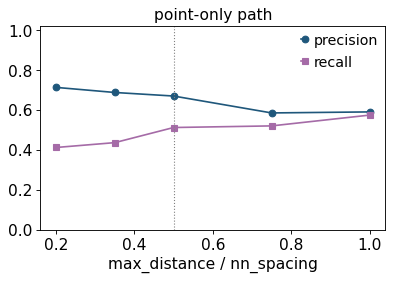

In [14]:
fig, ax = plt.subplots(figsize=(4.8, 3.4), constrained_layout=True)
ax.plot(sweep.index, sweep.precision, "o-", label="precision")
ax.plot(sweep.index, sweep.recall, "s-", label="recall")
ax.axvline(0.5, color="grey", ls=":", lw=1)
ax.set_xlabel("max_distance / nn_spacing"); ax.set_ylim(0, 1.02)
ax.legend(frameon=False); ax.set_title("point-only path")
plt.show()

Tightening the cap raises precision only a little (0.67 → 0.71 at 0.2 ×
spacing) and costs a lot of recall (0.51 → 0.41); loosening it buys some
recall (0.58 at one spacing) with more wrong pairs (precision 0.59). The
trade-off is real but shallow, because the limiting factor here is the warp,
not the cap: no setting comes near the 0.997 / 1.0 the image-assisted run
reached with the default. Tune `max_distance` for the use — strict for labels
you must trust, looser for coverage statistics — after the warp is right.

## 9. Pitfalls

### 9.1 A mirrored slide

Slides are sometimes imaged upside down, which mirrors one round. No rotation
can undo a mirror, so the search must include flips (`allow_flip=True`, the
default in both functions). Here we mirror the moving centroids and run the
point-only matcher with and without the flip search.

In [15]:
mirrored = moving_xy * np.array([-1.0, 1.0]) + np.array([HM, 0.0])
rows = []
for flip in (True, False):
    p, inf = ov.space.geom.match_cells(fixed_xy, mirrored, fixed_ids=fixed_ids,
                                       moving_ids=moving_ids, allow_flip=flip, return_info=True)
    s = score(p, f"allow_flip={flip}")
    s["det(affine)"] = np.linalg.det(inf["affine_matrix"])
    rows.append(s)
pd.DataFrame(rows).round(3)

                  pairs  correct  precision  recall  \
allow_flip=True   282.0    189.0      0.670   0.512   
allow_flip=False  149.0      4.0      0.027   0.011   

                  median distance / spacing  det(affine)  
allow_flip=True                       0.058       -0.820  
allow_flip=False                      0.039        0.841  

With the flip search, the negative determinant of the recovered affine reports
the mirror and the matching is as good as on the original orientation. Without
it, the best rotation of a mirrored point set is meaningless and the result
collapses. Keep `allow_flip=True` unless you are certain of the orientation —
then turning it off halves the search.

### 9.2 Different pixel sizes

The default scale grid (0.8–1.25 for centroids, 0.92–1.08 refined for images)
covers stage and focus differences, **not** different objectives. If the H&E
was scanned at 0.25 µm/px and the DAPI at 0.5 µm/px, the moving coordinates
are twice as large. Convert both rounds to the same physical unit (µm) first —
or, failing that, put the known ratio in `scales`.

In [16]:
rows = []
moving_2x = moving_xy * 2.0                                  # finer H&E scan: 2x pixel coordinates
p = ov.space.geom.match_cells(fixed_xy, moving_2x, fixed_ids=fixed_ids, moving_ids=moving_ids)
rows.append(score(p, "2x pixel size, default scales"))
p = ov.space.geom.match_cells(fixed_xy, moving_2x / 2.0, fixed_ids=fixed_ids, moving_ids=moving_ids)
rows.append(score(p, "converted to a common unit"))
pd.DataFrame(rows).round(3)

                               pairs  correct  precision  recall  \
2x pixel size, default scales   81.0      1.0      0.012   0.003   
converted to a common unit     282.0    189.0      0.670   0.512   

                               median distance / spacing  
2x pixel size, default scales                      0.013  
converted to a common unit                         0.058  

Outside its scale grid the coarse search cannot find the pose and the
matching fails; after converting to a common unit it is back to the
section-5 result.

### 9.3 RGB images need the `*_rgb` flag

`register_images` and the image path of `match_cells` work on 2-D nuclear
images. An RGB array is refused with a clear message instead of being
silently averaged to grey (which would have the inverted nuclear contrast
shown in section 2):

In [17]:
try:
    ov.space.geom.register_images(dapi, he_rgb)
except ValueError as e:
    print("ValueError:", e)

ValueError: register_images needs 2-D images (pass *_rgb=True for RGB)


Pass `moving_rgb=True` (or `fixed_rgb=True`), or convert yourself with
`hematoxylin_channel`. If your "H&E" is already a single-channel greyscale
scan, invert it before registering, or the bright-nuclei assumption breaks.

### 9.4 Unmatched cells are an answer, not a failure

Do not expect every cell to get a partner, and do not force one (e.g. by a
very large `max_distance`). Here is where the unmatched DAPI cells of the
image-assisted run come from:

In [18]:
unmatched = fixed_ids[~np.isin(fixed_ids, pairs_img.fixed_id)]
section_ids = unmatched[unmatched >= 0]
in_moving_field = np.all((mov_true[section_ids] > 3) & (mov_true[section_ids] < HM - 3), axis=1)
pd.Series({
    "unmatched DAPI cells": len(unmatched),
    "spurious DAPI detections": int((unmatched < 0).sum()),
    "nucleus outside the H&E field": int((~in_moving_field).sum()),
    "nucleus missed by the H&E segmentation": int((in_moving_field & ~kept_m[section_ids]).sum()),
    "true partner exists but not matched": int((in_moving_field & kept_m[section_ids]).sum()),
}).to_frame("cells")

                                        cells
unmatched DAPI cells                       56
spurious DAPI detections                   23
nucleus outside the H&E field              10
nucleus missed by the H&E segmentation     23
true partner exists but not matched         0

Every unmatched cell has a reason that lies in the data — a spurious object,
a nucleus outside the other field, or a segmentation miss on the other side.
In a real analysis you cannot see this ground truth, so keep the unmatched
cells explicit (e.g. as `NaN` in the transferred columns) rather than imputing
them from a neighbour.

### 9.5 More practical notes

- **Which side is fixed.** The matching does not depend on it, but the warp
  and `warped_moving` live in the fixed frame. Choose the round whose
  coordinates you want to keep (usually the molecular one) as *fixed*.
- **Images must be in the centroid frames.** The centroids must be pixel
  coordinates of exactly the images you pass (same crop, same downsampling).
  If you segmented on a full-resolution image but register a thumbnail, scale
  the coordinates accordingly.
- **Runtime.** The full pose search of `register_images` dominates (minutes
  for a few hundred thousand pixels). For very large slides, register a
  downsampled pair first and narrow `rotations` / `scales` for the
  full-resolution run, as done in sections 7 and 8.
- **Very large deformations** (folds, tears) are not smooth; check the
  error/overlay map and the per-region match rate rather than one global
  number.

## 10. Summary

| Step | Call |
|---|---|
| H&E → nuclear image | `ov.space.geom.hematoxylin_channel(he_rgb)` |
| length unit | `ov.space.geom.nn_spacing(fixed_xy)` |
| image registration | `mapping, info = ov.space.geom.register_images(dapi, he_rgb, moving_rgb=True, return_info=True)` |
| cells, centroids only | `ov.space.geom.match_cells(fixed_xy, moving_xy)` |
| cells, with images (recommended) | `ov.space.geom.match_cells(fixed_xy, moving_xy, fixed_image=dapi, moving_image=he_rgb, moving_rgb=True)` |

The returned table (`moving_id, fixed_id, distance`) is one-to-one; join it
to your two cell tables to transfer annotations or intensities across rounds.

## References

- Ruifrok A. C., Johnston D. A. (2001). Quantification of histochemical
  staining by color deconvolution. *Analytical and Quantitative Cytology and
  Histology* 23(4):291–299.
- Lewis J. P. (1995). Fast normalized cross-correlation. *Vision Interface*,
  120–123.
- Bookstein F. L. (1989). Principal warps: thin-plate splines and the
  decomposition of deformations. *IEEE TPAMI* 11(6):567–585.
  doi:10.1109/34.24792
- Myronenko A., Song X. (2010). Point set registration: Coherent Point Drift.
  *IEEE TPAMI* 32(12):2262–2275. doi:10.1109/TPAMI.2010.46
- Evangelidis G. D., Psarakis E. Z. (2008). Parametric image alignment using
  enhanced correlation coefficient maximization. *IEEE TPAMI*
  30(10):1858–1865. doi:10.1109/TPAMI.2008.113
- Kuhn H. W. (1955). The Hungarian method for the assignment problem.
  *Naval Research Logistics Quarterly* 2:83–97. doi:10.1002/nav.3800020109
- Fischler M. A., Bolles R. C. (1981). Random sample consensus. *Communications
  of the ACM* 24(6):381–395. doi:10.1145/358669.358692